<a href="https://www.kaggle.com/code/qwerty29544/smoki?scriptVersionId=361419714" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import random
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set_style("dark") # Theme for plots as Dark
sns.set_palette("rocket")

seed = 19273862
random.seed(seed)
np.random.seed(seed)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/playground-series-s3e24/sample_submission.csv
/kaggle/input/playground-series-s3e24/train.csv
/kaggle/input/playground-series-s3e24/test.csv


In [2]:
train_df = pd.read_csv(os.path.join(dirname, "train.csv")).drop("id", axis = 1)
test_df = pd.read_csv(os.path.join(dirname, "test.csv"))

In [3]:
train_df.head()

,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,...,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,smoking
0,55,165,60,81.0,0.5,0.6,1,1,135,87,...,40,75,16.5,1,1.0,22,25,27,0,1
1,70,165,65,89.0,0.6,0.7,2,2,146,83,...,57,126,16.2,1,1.1,27,23,37,1,0
2,20,170,75,81.0,0.4,0.5,1,1,118,75,...,45,93,17.4,1,0.8,27,31,53,0,1
3,35,180,95,105.0,1.5,1.2,1,1,131,88,...,38,102,15.9,1,1.0,20,27,30,1,0
4,30,165,60,80.5,1.5,1.0,1,1,121,76,...,44,93,15.4,1,0.8,19,13,17,0,1


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159256 entries, 0 to 159255
Data columns (total 23 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   age                  159256 non-null  int64  
 1   height(cm)           159256 non-null  int64  
 2   weight(kg)           159256 non-null  int64  
 3   waist(cm)            159256 non-null  float64
 4   eyesight(left)       159256 non-null  float64
 5   eyesight(right)      159256 non-null  float64
 6   hearing(left)        159256 non-null  int64  
 7   hearing(right)       159256 non-null  int64  
 8   systolic             159256 non-null  int64  
 9   relaxation           159256 non-null  int64  
 10  fasting blood sugar  159256 non-null  int64  
 11  Cholesterol          159256 non-null  int64  
 12  triglyceride         159256 non-null  int64  
 13  HDL                  159256 non-null  int64  
 14  LDL                  159256 non-null  int64  
 15  hemoglobin       

In [5]:
rename_keys = {"height(cm)": "height_cm", 
                 "weight(kg)": "weight_kg",
                 "waist(cm)": "waist_cm",
                 "eyesight(right)": "eyesight_right",
                 "eyesight(left)": "eyesight_left",
                 "hearing(right)": "hearing_right",
                 "hearing(left)": "hearing_left",
                 "fasting blood sugar": "fasting_blood_sugar",
                 "Urine protein": "urine_protein",
                 "serum creatinine": "serum_creatinine",
                 "dental caries": "dental_caries"}
train_df.rename(columns = rename_keys, inplace = True)

- Age - возраст (полных лет)
- heigth  - рост в сантиметрах
- weight - вес в кг
- waist - талия в сантиметрах
- eyesight (left)
- eyesight (right)
- hearing (left)
- hearing (right)
- systolic - систолическое давление ()
- relaxation - ударов в минуту в покое
- fasting blood sugar - сахар в крови натощак
- cholesterol - холестерин (Общий холестерин (CHOL). Норма – 3,2−5,6 ммоль/л)
- triglyceride - Триглицериды (TG). Норма – 0,41−1,8 ммоль/л
- HDL - Холестерин-ЛПВП (HDL). Норма – не менее 0,9 ммоль/л
- LDL - Холестерин-ЛПНП (LDL). Норма – 1,71−3,5 ммоль/л
- hemoglobin - гемоглобин
- Urine protein - содержание протеинов 
- serum creatinine - сывороточный креатинин
- AST - АСТ (или АсАт) — аспартатаминотрансфераза;  
- ALT - АЛТ (или АлАт) — аланинаминотрансфераза; **ОТНОШЕНИЕ** АСТ/АЛТ — коэффициент де Ритиса. В норме он составляет 1,33±0,42 или 0,91-1,75.
- Gtp - ГГТ (или гамма-глютамилтранспептидаза — ГГТП) — гамма-глутамилтрансфераза; 
- dental caries - числовая переменная (0/1) нет ли у человека кариеса или есть
- smoking - числовая переменная (0/1) не курит ли человек или курит 


Возраст	Норма гемоглобина, г/л
- 1 день	152–235
- 2–13 дней	150–240
- 14–23 дня	127–187
- 24–30 дней	103–179
- 1 месяц	90–166
- 2 месяца	92–150
- 3 месяца	96–135
- 4 месяца	96–135
- 5–7 месяцев	101–132
- 8–10 месяцев	105–135
- 11 месяцев	107–131
- 12 месяцев — 4 года	108–132
- 5–9 лет	111–143
- 10–11 лет	119–147
- 12–14 лет (мальчики)	120–160
- 12–14 лет (девочки)	115–150
- 15–17 лет (юноши)	117–166
- 15–17 лет (девушки)	117–153
Мужчины
- 18 лет — 44 года	132–173
- 45 лет — 64 года	131–172
- От 65 лет	126–174
Женщины
- 18 лет — 44 года	117–155
- 45 лет — 64 года	117–160
- От 65 лет	117–161

Возраст	Допустимые значения, мкмоль/л
- До 1 месяца	19 – 78
- От 1 месяца до 1 года	14 – 35
- 1-3 года	20 – 37
- 3-5 лет	25 – 45
- 5-8 лет	30 – 56
- 8-10 лет	34 – 57
- 10-13 лет	45 – 62
- Старше 18 лет (женский пол)	53 – 97
- Женщины старше 50 лет	53 – 106
- Старше 15 лет	80 – 150
- Мужчины старше 60 лет	71 – 115

In [6]:
train_df.describe()

,age,height_cm,weight_kg,waist_cm,eyesight_left,eyesight_right,hearing_left,hearing_right,systolic,relaxation,...,HDL,LDL,hemoglobin,urine_protein,serum_creatinine,AST,ALT,Gtp,dental_caries,smoking
count,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,...,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000,159256.000000
mean,44.306626,165.266929,67.143662,83.001990,1.005798,1.000989,1.023974,1.023421,122.503648,76.874071,...,55.852684,114.607682,14.796965,1.074233,0.892764,25.516853,26.550296,36.216004,0.197996,0.437365
std,11.842286,8.818970,12.586198,8.957937,0.402113,0.392299,0.152969,0.151238,12.729315,8.994642,...,13.964141,28.158931,1.431213,0.347856,0.179346,9.464882,17.753070,31.204643,0.398490,0.496063
min,20.000000,135.000000,30.000000,51.000000,0.100000,0.100000,1.000000,1.000000,77.000000,44.000000,...,9.000000,1.000000,4.900000,1.000000,0.100000,6.000000,1.000000,2.000000,0.000000,0.000000
25%,40.000000,160.000000,60.000000,77.000000,0.800000,0.800000,1.000000,1.000000,114.000000,70.000000,...,45.000000,95.000000,13.800000,1.000000,0.800000,20.000000,16.000000,18.000000,0.000000,0.000000
50%,40.000000,165.000000,65.000000,83.000000,1.000000,1.000000,1.000000,1.000000,121.000000,78.000000,...,54.000000,114.000000,15.000000,1.000000,0.900000,24.000000,22.000000,27.000000,0.000000,0.000000
75%,55.000000,170.000000,75.000000,89.000000,1.200000,1.200000,1.000000,1.000000,130.000000,82.000000,...,64.000000,133.000000,15.800000,1.000000,1.000000,29.000000,32.000000,44.000000,0.000000,1.000000
max,85.000000,190.000000,130.000000,127.000000,9.900000,9.900000,2.000000,2.000000,213.000000,133.000000,...,136.000000,1860.000000,21.000000,6.000000,9.900000,778.000000,2914.000000,999.000000,1.000000,1.000000


In [7]:
train_df

,age,height_cm,weight_kg,waist_cm,eyesight_left,eyesight_right,hearing_left,hearing_right,systolic,relaxation,...,HDL,LDL,hemoglobin,urine_protein,serum_creatinine,AST,ALT,Gtp,dental_caries,smoking
0,55,165,60,81.0,0.5,0.6,1,1,135,87,...,40,75,16.5,1,1.0,22,25,27,0,1
1,70,165,65,89.0,0.6,0.7,2,2,146,83,...,57,126,16.2,1,1.1,27,23,37,1,0
2,20,170,75,81.0,0.4,0.5,1,1,118,75,...,45,93,17.4,1,0.8,27,31,53,0,1
3,35,180,95,105.0,1.5,1.2,1,1,131,88,...,38,102,15.9,1,1.0,20,27,30,1,0
4,30,165,60,80.5,1.5,1.0,1,1,121,76,...,44,93,15.4,1,0.8,19,13,17,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159251,40,155,45,69.0,1.5,2.0,1,1,127,80,...,72,159,14.5,1,0.8,25,26,13,0,0
159252,50,155,75,82.0,1.0,1.0,1,1,120,80,...,64,108,14.5,1,0.6,21,20,18,0,0
159253,40,160,50,66.0,1.5,1.0,1,1,114,70,...,87,93,10.9,1,0.6,15,9,12,0,0
159254,50,165,75,92.0,1.2,1.0,1,1,121,90,...,55,80,14.4,1,1.1,22,17,37,0,1


In [8]:
fig,axes = plt.subplots(len(train_df.columns),2,figsize=(15,len(train_df.columns)*2),dpi=300)

for ind,col in enumerate(train_df.columns):
    
    plt.subplot(len(train_df.columns),2,2*ind+1)
    sns.histplot(train_df,x=col,bins=40,kde=True);
    plt.gca().set_title(col)
        
    plt.subplot(len(train_df.columns),2,2*ind+2)
    sns.boxplot(train_df,x=col,orient="h",palette="flare")
    plt.gca().set_title(col)
    
fig.tight_layout()
plt.show()

In [9]:
def new_cols_to_df(df):
    cols_to_log = ["eyesight_left", "eyesight_right", 
                   "LDL", "serum_creatinine", "AST", "ALT", "Gtp", "fasting_blood_sugar"]
    new_names = ["log_" + x for x in cols_to_log]
    
    df[new_names] = df[cols_to_log].apply(lambda x: np.log(x + 1))
    
    df["BMI"] = df["weight_kg"] / ((df["height_cm"] / 100) ** 2)
    
    df["thickness"] = df["waist_cm"] / df["height_cm"]
    
    df["log_de_Ritis"] = np.log(df["AST"] / df["ALT"] + 1)
    
    df["log_eyesight_rel"] = np.log(df["eyesight_left"] * df["eyesight_right"]/(((df["eyesight_left"] * df["eyesight_right"]) / 2)**2) + 1)
    
    df = df.query("""eyesight_left <= 4.0 & eyesight_right <= 4.0""")
    df = df.drop(["hearing_left","hearing_right"], axis = 1)
    df = df.drop(cols_to_log, axis = 1)
    
    return df

def new_cols_to_df_test(df):
    cols_to_log = ["eyesight_left", "eyesight_right", 
                   "LDL", "serum_creatinine", "AST", "ALT", "Gtp", "fasting_blood_sugar"]
    new_names = ["log_" + x for x in cols_to_log]
    
    df[new_names] = df[cols_to_log].apply(lambda x: np.log(x + 1))
    
    df["BMI"] = df["weight_kg"] / ((df["height_cm"] / 100) ** 2)
    
    df["thickness"] = df["waist_cm"] / df["height_cm"]
    
    df["log_de_Ritis"] = np.log(df["AST"] / df["ALT"] + 1)
    
    df["log_eyesight_rel"] = np.log(df["eyesight_left"] * df["eyesight_right"]/(((df["eyesight_left"] * df["eyesight_right"]) / 2)**2) + 1)
    
    df = df.drop(["hearing_left","hearing_right"], axis = 1)
    df = df.drop(cols_to_log, axis = 1)    
    return df

In [10]:
new_df = new_cols_to_df(train_df)

In [11]:
fig,axes = plt.subplots(len(new_df.columns),2,figsize=(15,len(new_df.columns)*2),dpi=300)

for ind,col in enumerate(new_df.columns):
    
    plt.subplot(len(new_df.columns),2,2*ind+1)
    sns.histplot(new_df,x=col,bins=40,kde=True);
    plt.gca().set_title(col)
        
    plt.subplot(len(new_df.columns),2,2*ind+2)
    sns.boxplot(new_df,x=col,orient="h",palette="flare")
    plt.gca().set_title(col)
    
fig.tight_layout()
plt.show()

In [12]:
X = new_df.drop("smoking", axis = 1)
Y = new_df["smoking"]

In [13]:
from sklearn.decomposition import PCA, NMF
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

In [14]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, 
                                                    test_size = 0.2, 
                                                    random_state = seed, 
                                                    shuffle = True, 
                                                    stratify = Y)

In [15]:
PCA_model_2d = PCA(n_components = 2)
NMF_model_2d = NMF(n_components = 2)

PCA_model_2d.fit(X_train)
NMF_model_2d.fit(X_train)

NMF(n_components=2)

In [16]:
X_train_2dPCA = PCA_model_2d.transform(X_train)
X_test_2dPCA = PCA_model_2d.transform(X_test)

X_train_2dNMF = NMF_model_2d.transform(X_train)
X_test_2dNMF = NMF_model_2d.transform(X_test)

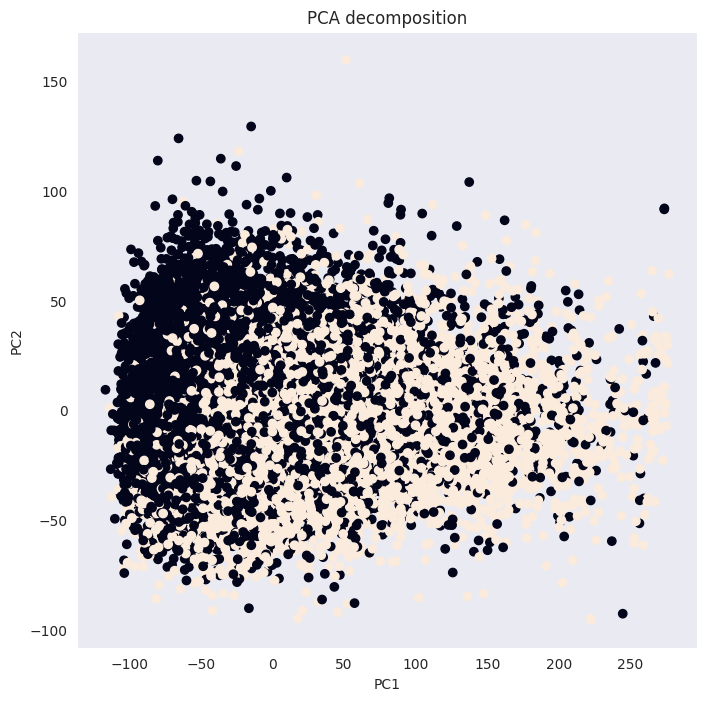

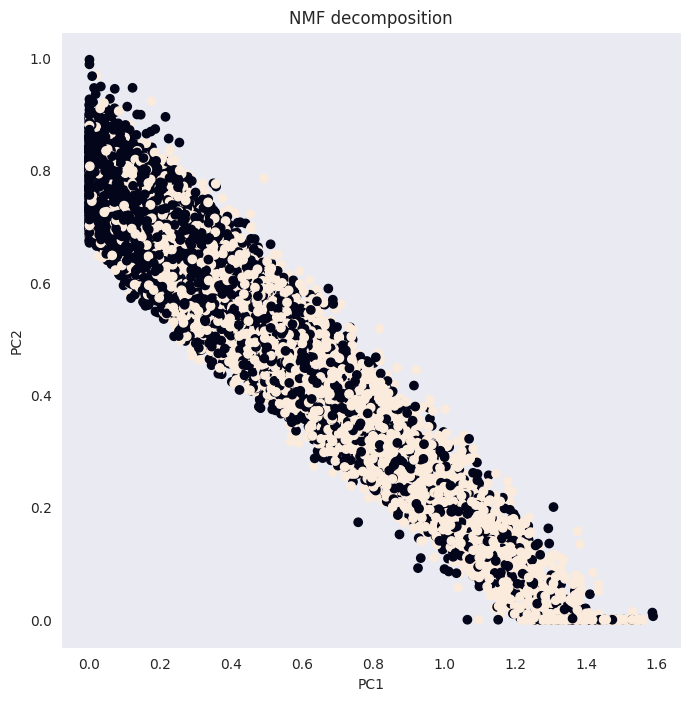

In [17]:
plt.figure(figsize = (8, 8), dpi = 100)
plt.title("PCA decomposition")
plt.scatter(X_test_2dPCA[:, 0], X_test_2dPCA[:, 1], c = Y_test)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

plt.figure(figsize = (8, 8), dpi = 100)
plt.title("NMF decomposition")
plt.scatter(X_test_2dNMF[:, 0], X_test_2dNMF[:, 1], c = Y_test)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm

In [19]:
torch.tensor([16, 2, -19], dtype = torch.float)

tensor([ 16.,   2., -19.])

In [20]:
fc1 = nn.Linear(24, 12)

In [21]:
fc1(torch.randn(100 * 24).reshape(100, 24)).shape

torch.Size([100, 12])

In [22]:
ReLU1 = nn.ReLU()

In [23]:
ReLU1(fc1(torch.randn(100 * 24).reshape(100, 24)))

tensor([[0.5297, 0.0452, 0.7425,  ..., 1.1532, 0.0000, 1.0170],
        [0.1187, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
        [0.6128, 0.0286, 1.0089,  ..., 0.0000, 0.0000, 0.2776],
        ...,
        [0.0000, 0.0000, 0.1033,  ..., 0.0000, 0.0000, 0.3010],
        [0.4677, 0.0000, 0.0000,  ..., 0.3214, 0.2932, 0.0000],
        [0.3103, 0.1294, 0.5271,  ..., 0.0000, 0.0000, 0.7115]],
       grad_fn=<ReluBackward0>)

In [24]:
nn.Sigmoid()(fc1(torch.randn(100 * 24).reshape(100, 24)))

tensor([[0.3612, 0.4659, 0.5466,  ..., 0.7232, 0.6515, 0.4254],
        [0.3472, 0.3294, 0.2704,  ..., 0.4527, 0.5703, 0.2916],
        [0.5754, 0.3620, 0.3280,  ..., 0.6241, 0.7130, 0.5680],
        ...,
        [0.6160, 0.4050, 0.6506,  ..., 0.6424, 0.5795, 0.6640],
        [0.3915, 0.4734, 0.6148,  ..., 0.4764, 0.5351, 0.6124],
        [0.5012, 0.4797, 0.5274,  ..., 0.6144, 0.5153, 0.5749]],
       grad_fn=<SigmoidBackward0>)

In [25]:
# Define the neural network model
class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, num_classes)
        self.sm = nn.Softmax(dim = 1)
    
    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        return out
    
    def evaluation(self, x):
        out = self.sm(self.forward(x))
        return out

# Define a function to update the live loss plot during training
def update_plot(train_losses, val_losses):
    plt.close()
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

In [26]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

X_train_tensor = torch.tensor(X_train.to_numpy(), dtype = torch.float).to(device)
X_test_tensor = torch.tensor(X_test.to_numpy(), dtype = torch.float).to(device)
Y_train_tensor = torch.tensor(Y_train.to_numpy(), dtype = torch.long).to(device)
Y_test_tensor = torch.tensor(Y_test.to_numpy(), dtype = torch.long).to(device)

# Set hyperparameters
input_size = X_train_tensor.shape[1]
hidden_size = 50
num_classes = len(Y_train_tensor.unique())
learning_rate = 0.002
num_epochs = 1000
batch_size = 2500

# Create the model instance
model = NeuralNet(input_size, hidden_size, num_classes)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    model = model.to(device)
    running_loss = 0.0
    order = np.random.permutation(len(X_train_tensor))
    for start_index in range(0, len(X_train_tensor), batch_size):
        optimizer.zero_grad()
        
        batch_indexes = order[start_index:start_index+batch_size]
        
        x_batch = X_train_tensor[batch_indexes,:]
        y_batch = Y_train_tensor[batch_indexes]

        y_pred = model.forward(x_batch)
        loss = criterion(y_pred, y_batch)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
    train_losses.append(running_loss/len(X_train_tensor) * batch_size)
    
    # Evaluate the model on the validation set
    with torch.no_grad():
        val_loss = 0.0
        Y_test_pred = model(X_test_tensor)
        loss = criterion(Y_test_pred, Y_test_tensor)
        val_loss += loss.item()
        val_losses.append(val_loss)
    
    # Update the live loss plot
    #update_plot(train_losses, val_losses)
    if epoch % 50 == 0:
        print(f"epoch №{epoch}: train_score is {round(train_losses[-1], 4)}, val_score is {round(val_losses[-1], 4)}")

epoch №0: train_score is 1.099, val_score is 0.6066
epoch №50: train_score is 0.4815, val_score is 0.4775
epoch №100: train_score is 0.4684, val_score is 0.4826
epoch №150: train_score is 0.4626, val_score is 0.4609
epoch №200: train_score is 0.4585, val_score is 0.4615
epoch №250: train_score is 0.4587, val_score is 0.4571
epoch №300: train_score is 0.4555, val_score is 0.4587
epoch №350: train_score is 0.455, val_score is 0.4549
epoch №400: train_score is 0.4521, val_score is 0.4546
epoch №450: train_score is 0.4529, val_score is 0.4554
epoch №500: train_score is 0.4509, val_score is 0.4527
epoch №550: train_score is 0.4499, val_score is 0.4521
epoch №600: train_score is 0.4504, val_score is 0.4572
epoch №650: train_score is 0.4508, val_score is 0.4567
epoch №700: train_score is 0.4495, val_score is 0.4521
epoch №750: train_score is 0.4491, val_score is 0.4534
epoch №800: train_score is 0.4493, val_score is 0.4554
epoch №850: train_score is 0.4496, val_score is 0.4541
epoch №900: tra

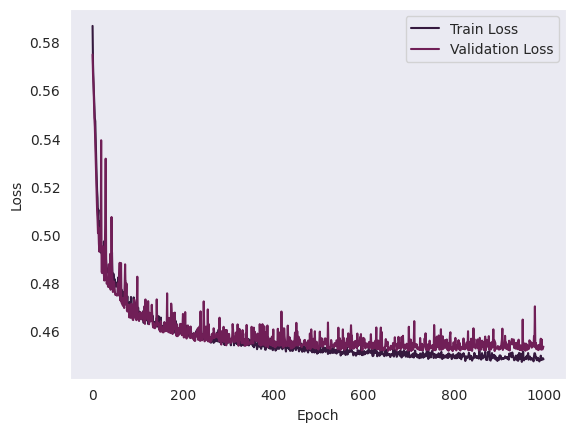

In [27]:
update_plot(train_losses[1:], val_losses[1:])

In [28]:
answers_test = torch.argmax(model.evaluation(X_test_tensor), axis = 1).to("cpu")

In [29]:
from sklearn.metrics import roc_auc_score

In [30]:
roc_auc_score(Y_test_tensor.to("cpu"), answers_test)

0.7754626839377278

In [31]:
test_df.rename(columns = rename_keys, inplace=True)
test_df.set_index("id", inplace=True)

In [32]:
new_test = new_cols_to_df_test(test_df)
X_test = torch.tensor(new_test.to_numpy(), dtype = torch.float).to(device)

In [33]:
predictions = model.evaluation(X_test).to("cpu")[:, 1].detach().numpy()

In [34]:
pred_df = pd.DataFrame({"id": new_test.index, "smoking": np.array(predictions)})
pred_df.to_csv("submission.csv", index=False)